# DateWise: AI-Powered Speed Dating and Strategic Matchmaking

## First-project modelling notebook

**Objective:** Explore whether information available before a speed date can help estimate whether a pair will mutually match.

This notebook documents the complete first modelling attempt, from raw-data inspection to a held-out evaluation of logistic regression. The emphasis is on a transparent and reproducible workflow—not on claiming that the model is already accurate enough for real-world matchmaking.

### Project scope
- Dataset: the Kaggle speed-dating dataset (`Speed Dating Data.csv`).
- Prediction target: `match` (0 = no mutual match, 1 = mutual match).
- Model family: logistic regression only.
- Preprocessing: median imputation and standardisation.
- Validation strategy: split by `wave` so that waves do not overlap between training and testing.

> **Before running:** Keep `Speed Dating Data.csv` in the same folder as this notebook, or update the path in the data-loading cell below.

## 1. Imports

All libraries used in this notebook are imported here so dependencies are easy to review and the code can be run from a fresh kernel.

In [130]:
# Data handling
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")


# Data splitting and preprocessing
from sklearn.model_selection import GroupShuffleSplit
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Model
from sklearn.linear_model import LogisticRegression

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    roc_auc_score,
)

## 2. Load and inspect the dataset

We load the Kaggle speed-dating dataset and inspect its dimensions, sample records, summary statistics, data types, and column names. The file is read with `cp1252` encoding to handle its character encoding correctly.

In [131]:
df = pd.read_csv(
    "../data/Speed Dating Data.csv",
    encoding="cp1252"
)

print("Dataset dimensions:")
print(df.shape)

print("\nFirst five rows:")
print(df.head())

print("\nRandom five rows:")
print(df.sample(5, random_state=42))

print("\nStatistical summary:")
print(df.describe(include='all').T)

print("\nDataset information:")
df.info()

print("\nDataset columns:")
print(df.columns.to_list())

Dataset dimensions:
(8378, 195)

First five rows:
   iid   id  gender  idg  condtn  wave  round  position  positin1  order  ...  \
0    1  1.0       0    1       1     1     10         7       NaN      4  ...   
1    1  1.0       0    1       1     1     10         7       NaN      3  ...   
2    1  1.0       0    1       1     1     10         7       NaN     10  ...   
3    1  1.0       0    1       1     1     10         7       NaN      5  ...   
4    1  1.0       0    1       1     1     10         7       NaN      7  ...   

   attr3_3  sinc3_3  intel3_3  fun3_3  amb3_3  attr5_3  sinc5_3  intel5_3  \
0      5.0      7.0       7.0     7.0     7.0      NaN      NaN       NaN   
1      5.0      7.0       7.0     7.0     7.0      NaN      NaN       NaN   
2      5.0      7.0       7.0     7.0     7.0      NaN      NaN       NaN   
3      5.0      7.0       7.0     7.0     7.0      NaN      NaN       NaN   
4      5.0      7.0       7.0     7.0     7.0      NaN      NaN       NaN   



## 3. Initial data-quality checks

We check for exact duplicate rows and review the candidate variables that may be available before a date. The feature report records data types, missingness, and the number of distinct values.

The exploratory preference checks below examine whether the six stated partner-preference scores approximately add up to 100. These checks help us understand the data; they do not automatically remove observations.

In [132]:
# Revised Time 1 candidate features

candidate_features = [
    # Demographic information
    "gender", "age", "age_o",
    "field_cd", "career_c", "goal", "date", "go_out",

    # Lifestyle interests
    "sports", "tvsports", "exercise", "dining",
    "museums", "art", "hiking", "gaming",
    "clubbing", "reading", "tv", "theater",
    "movies", "concerts", "music", "shopping", "yoga",

    # Expectations before the event
    "exphappy",

    # Self-assessment
    "attr3_1", "sinc3_1", "intel3_1",
    "fun3_1", "amb3_1",

    # Personal preferences
    "attr1_1", "sinc1_1", "intel1_1",
    "fun1_1", "amb1_1", "shar1_1",

    # Partner's stated preferences
    "pf_o_att", "pf_o_sin", "pf_o_int",
    "pf_o_fun", "pf_o_amb", "pf_o_sha",

    # Pre-date interest correlation
    "int_corr"
]

# Feature report
feature_report = pd.DataFrame({
    "dtype": df[candidate_features].dtypes,
    "missing_count": df[candidate_features].isnull().sum(),
    "missing_percentage": (
        df[candidate_features].isnull().mean() * 100
    ).round(2),
    "unique_values": df[candidate_features].nunique()
})

print("FEATURE REPORT")
print(feature_report.sort_values(
    "missing_percentage",
    ascending=False
).to_string())


print("\nWAVE COUNTS:")
print(df["wave"].value_counts().sort_index())

FEATURE REPORT
            dtype  missing_count  missing_percentage  unique_values
int_corr  float64            158                1.89            155
career_c  float64            138                1.65             17
pf_o_sha  float64            129                1.54             85
shar1_1   float64            121                1.44             85
pf_o_amb  float64            107                1.28             82
fun3_1    float64            105                1.25              9
attr3_1   float64            105                1.25              9
sinc3_1   float64            105                1.25              9
intel3_1  float64            105                1.25              8
amb3_1    float64            105                1.25              9
age_o     float64            104                1.24             24
exphappy  float64            101                1.21             10
amb1_1    float64             99                1.18             82
pf_o_fun  float64             98 

## 4. Constructing reciprocal pair records

The raw data is organised as directed interactions: a row for participant A evaluating participant B is distinct from the reverse row for B evaluating A.

For a mutual-match task, we want one record per unordered pair. We first inspect whether reverse interactions exist and whether the two directions agree on the `match` label. We then retain one direction per reciprocal pair (`iid < pid`) to avoid counting the same pair twice.

In [133]:
pair_check = df.merge(
    df[["iid", "pid"]],
    left_on=["pid", "iid"],
    right_on=["iid", "pid"],
    how="left",
    indicator=True
)

print(pair_check["_merge"].value_counts())

_merge
both          8368
left_only       10
right_only       0
Name: count, dtype: int64


/tmp/ipykernel_5874/1292263716.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  pair_check = df.merge(
/tmp/ipykernel_5874/1292263716.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  pair_check = df.merge(


In [134]:
# Keep only records that have a reciprocal interaction
reciprocal = df.merge(
    df[["iid", "pid", "match"]],
    left_on=["pid", "iid"],
    right_on=["iid", "pid"],
    how="inner",
    suffixes=("", "_reverse")
)

# Check whether match labels agree
inconsistent_matches = reciprocal[
    reciprocal["match"] != reciprocal["match_reverse"]
]

# Select and rename columns for checking reverse interactions
reverse_records = df[["iid", "pid"]].rename(
    columns={
        "iid": "iid_reverse",
        "pid": "pid_reverse"
    }
)

# Keep only records that have a reverse interaction
reciprocal_df = df.merge(
    reverse_records,
    left_on=["pid", "iid"],
    right_on=["iid_reverse", "pid_reverse"],
    how="inner"
)

# Keep only one direction of each pair
pairs_df = reciprocal_df[
    reciprocal_df["iid"] < reciprocal_df["pid"]
].copy()

print("Original directed records:", len(df))
print("Reciprocal directed records:", len(reciprocal_df))
print("Unique pair-level records:", len(pairs_df))
print(
    "Unique participant pairs:",
    pairs_df[["iid", "pid"]].drop_duplicates().shape[0]
)

Original directed records: 8378
Reciprocal directed records: 8368
Unique pair-level records: 4184
Unique participant pairs: 4184


## 5. Building participant-level and pair-level features

We select participant attributes that are intended to be known before the date. One row is retained per participant, and we verify that the selected participant-level values are consistent across that participant's records.

Next, each pair is represented symmetrically:
- **Numerical variables:** pair mean and absolute difference.
- **Categorical variables:** an indicator for whether both participants share the same category.

This representation avoids making the feature vector depend on which participant happened to be listed first. Missing categorical values are preserved as missing rather than being treated as a disagreement.

In [135]:
# Select participant-level features
participant_features = [
    "gender",
    "age",
    "field_cd",
    "career_c",
    "goal",
    "date",
    "go_out",
    "sports",
    "tvsports",
    "exercise",
    "dining",
    "museums",
    "art",
    "hiking",
    "gaming",
    "clubbing",
    "reading",
    "tv",
    "theater",
    "movies",
    "concerts",
    "music",
    "shopping",
    "yoga",
    "exphappy",
    "attr1_1",
    "sinc1_1",
    "intel1_1",
    "fun1_1",
    "amb1_1",
    "shar1_1",
    "attr3_1",
    "sinc3_1",
    "intel3_1",
    "fun3_1",
    "amb3_1"
]

# Keep one record per participant
participants = (
    df[["iid"] + participant_features]
    .drop_duplicates(subset="iid")
    .copy()
)

print("Number of participants:", len(participants))
print("Unique participant IDs:", participants["iid"].nunique())

Number of participants: 551
Unique participant IDs: 551


In [136]:
participants_A = participants.rename(
    columns={col: f"{col}_A" for col in participant_features}
)
participants_B = participants.rename(
    columns={
        "iid": "pid",
        **{col: f"{col}_B" for col in participant_features}
    }
)

pair_features = pairs_df[["iid", "pid", "match"]].copy()
pair_features = pair_features.merge(
    participants_A, 
    on="iid",
    how = "left",
    validate = "many_to_one"
)

pair_features = pair_features.merge(
    participants_B,
    on="pid",
    how="left",
    validate="many_to_one"
)

print("Pair-level dataset shape:", pair_features.shape)
print("\nFirst five rows:")
print(pair_features.head())

Pair-level dataset shape: (4184, 75)

First five rows:
   iid   pid  match  gender_A  age_A  field_cd_A  career_c_A  goal_A  date_A  \
0    1  11.0      0         0   21.0         1.0         NaN     2.0     7.0   
1    1  12.0      0         0   21.0         1.0         NaN     2.0     7.0   
2    1  13.0      1         0   21.0         1.0         NaN     2.0     7.0   
3    1  14.0      1         0   21.0         1.0         NaN     2.0     7.0   
4    1  15.0      1         0   21.0         1.0         NaN     2.0     7.0   

   go_out_A  ...  sinc1_1_B  intel1_1_B  fun1_1_B  amb1_1_B  shar1_1_B  \
0       1.0  ...       20.0        20.0      20.0       0.0        5.0   
1       1.0  ...        0.0         0.0      40.0       0.0        0.0   
2       1.0  ...       18.0        19.0      18.0      14.0       12.0   
3       1.0  ...        5.0        15.0      40.0       5.0        5.0   
4       1.0  ...       10.0        20.0      10.0      10.0       20.0   

   attr3_1_B  sinc3

In [137]:
print(
    "Unique pairs:",
    pair_features[["iid", "pid"]].drop_duplicates().shape[0]
)

print(
    "Missing A features:\n",
    pair_features[
        [f"{col}_A" for col in participant_features]
    ].isnull().sum().sum()
)

print(
     "Missing B features:",
    pair_features[
        [f"{col}_B" for col in participant_features]
    ].isnull().sum().sum()
)


Unique pairs: 4184
Missing A features:
 2179
Missing B features: 900


In [138]:
# Keep pair identifiers and target
pair_model_df = pair_features[["iid", "pid", "match"]].copy()

# Categorical features
categorical_features = [
    "gender",
    "field_cd",
    "career_c",
    "goal"
]

# All remaining features are treated as numerical
numeric_features = [
    col for col in participant_features
    if col not in categorical_features
]

# Create symmetric numerical features
for col in numeric_features:

    A = pair_features[f"{col}_A"]
    B = pair_features[f"{col}_B"]

    pair_model_df[f"{col}_mean"] = (A + B) / 2

    pair_model_df[f"{col}_diff"] = (A - B).abs()


# Create symmetric categorical features
for col in categorical_features:

    A = pair_features[f"{col}_A"]
    B = pair_features[f"{col}_B"]

    same = (A == B).astype(float)

    # Preserve missing values rather than treating them as differences
    same[A.isna() | B.isna()] = float("nan")

    pair_model_df[f"{col}_same"] = same


print("Original pair dataset:", pair_features.shape)
print("Symmetric feature dataset:", pair_model_df.shape)

print(pair_model_df.head())

Original pair dataset: (4184, 75)
Symmetric feature dataset: (4184, 71)
   iid   pid  match  age_mean  age_diff  date_mean  date_diff  go_out_mean  \
0    1  11.0      0      24.0       6.0        6.0        2.0          2.5   
1    1  12.0      0      21.5       1.0        4.0        6.0          1.0   
2    1  13.0      1      21.5       1.0        7.0        0.0          1.0   
3    1  14.0      1      22.0       2.0        5.5        3.0          1.0   
4    1  15.0      1      22.5       3.0        5.5        3.0          1.0   

   go_out_diff  sports_mean  ...  intel3_1_mean  intel3_1_diff  fun3_1_mean  \
0          3.0          8.5  ...            8.0            0.0          7.5   
1          0.0          9.0  ...            9.0            2.0          8.5   
2          0.0          8.0  ...            8.0            0.0          8.0   
3          0.0          9.5  ...            8.5            1.0          8.5   
4          0.0          9.0  ...            8.5            1.0  

In [139]:
# Check missing values in our engineered features
missing = pair_model_df.isnull().sum()

print("Features with missing values:")
print(missing[missing > 0].sort_values(ascending=False))


# Check features with only one unique value
print("\nUnique values in each feature:")

for col in pair_model_df.columns:
    if col not in ["iid", "pid", "match"]:
        print(col, ":", pair_model_df[col].nunique(dropna=False))

pair_model_df = pair_model_df.drop(columns=["gender_same"])

Features with missing values:
career_c_same    137
shar1_1_mean     119
shar1_1_diff     119
attr3_1_diff     105
intel3_1_diff    105
                ... 
intel1_1_mean     79
attr1_1_diff      79
shopping_diff     79
yoga_diff         79
goal_same         79
Length: 67, dtype: int64

Unique values in each feature:
age_mean : 42
age_diff : 25
date_mean : 12
date_diff : 8
go_out_mean : 12
go_out_diff : 8
sports_mean : 20
sports_diff : 11
tvsports_mean : 20
tvsports_diff : 11
exercise_mean : 20
exercise_diff : 11
dining_mean : 15
dining_diff : 11
museums_mean : 19
museums_diff : 12
art_mean : 19
art_diff : 12
hiking_mean : 20
hiking_diff : 12
gaming_mean : 23
gaming_diff : 16
clubbing_mean : 21
clubbing_diff : 11
reading_mean : 21
reading_diff : 13
tv_mean : 20
tv_diff : 11
theater_mean : 20
theater_diff : 12
movies_mean : 17
movies_diff : 12
concerts_mean : 19
concerts_diff : 12
music_mean : 17
music_diff : 11
shopping_mean : 20
shopping_diff : 11
yoga_mean : 21
yoga_diff : 11
exphappy

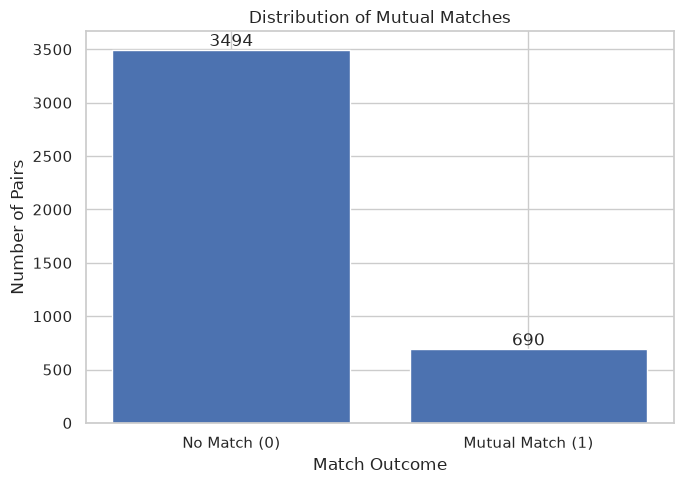

In [140]:

# Match vs No-Match Distribution

match_counts = pair_model_df["match"].value_counts().sort_index()

plt.figure(figsize=(7, 5))

bars = plt.bar(
    ["No Match (0)", "Mutual Match (1)"],
    match_counts.values
)

plt.title("Distribution of Mutual Matches")
plt.xlabel("Match Outcome")
plt.ylabel("Number of Pairs")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height)}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()


### 5.1 Wave-level exploration

We check how many waves participants appear in and summarise the number of pairs and match rate in each wave. This matters because observations from the same event wave may share context. The modelling split therefore keeps entire waves together.

In [141]:
# Count how many different waves each participant appears in
wave_check = df.groupby("iid")["wave"].nunique()

# Count participants belonging to 1, 2, 3, etc. waves
print(wave_check.value_counts().sort_index())

print(
    pairs_df.groupby("wave")
    .size()
    .sort_index()
)

wave
1    551
Name: count, dtype: int64
wave
1     100
2     304
3     100
4     324
5      90
6      25
7     256
8     100
9     400
10     81
11    441
12    196
13     90
14    360
15    342
16     48
17    140
18     36
19    225
20     42
21    484
dtype: int64


In [142]:
wave_stats = (
    pairs_df.groupby("wave")["match"]
    .agg(["count", "sum", "mean"])
)

wave_stats = wave_stats.rename(columns={
    "count": "total_pairs",
    "sum": "successful_matches",
    "mean": "match_rate"
})

wave_stats["match_rate"] *= 100

print(wave_stats.round(2))

      total_pairs  successful_matches  match_rate
wave                                             
1             100                  31       31.00
2             304                  31       10.20
3             100                  13       13.00
4             324                  65       20.06
5              90                  27       30.00
6              25                   5       20.00
7             256                  43       16.80
8             100                  18       18.00
9             400                  62       15.50
10             81                  15       18.52
11            441                  64       14.51
12            196                  21       10.71
13             90                  16       17.78
14            360                  63       17.50
15            342                  63       18.42
16             48                  12       25.00
17            140                  24       17.14
18             36                   3        8.33


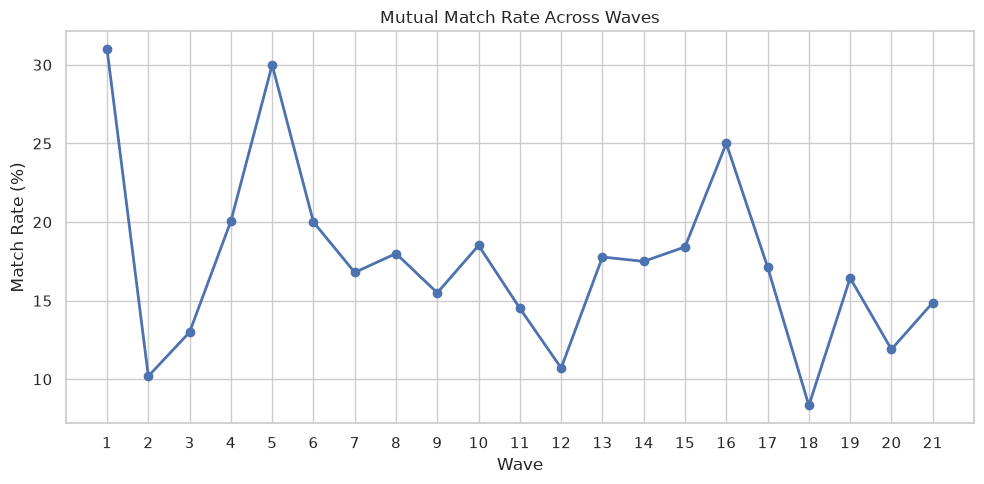

In [143]:

# Match Rate Across Waves

plt.figure(figsize=(10, 5))

plt.plot(
    wave_stats.index,
    wave_stats["match_rate"],
    marker="o",
    linewidth=2
)

plt.title("Mutual Match Rate Across Waves")
plt.xlabel("Wave")
plt.ylabel("Match Rate (%)")

plt.xticks(wave_stats.index)
plt.grid(True)

plt.tight_layout()
plt.show()


## 6. Train/test split by wave

We attach the wave identifier to each pair and use `GroupShuffleSplit` with `wave` as the grouping variable.

This is stricter than a random row split: no wave can appear in both training and testing. It gives us a test of whether the model transfers to held-out waves, rather than merely recognising patterns from waves it has already seen.

In [144]:
pair_model_df = pair_model_df.drop(columns=["wave"], errors="ignore")

pair_model_df = pair_model_df.merge(
    pairs_df[["iid", "pid", "wave"]],
    on=["iid", "pid"],
    how="left",
    validate="one_to_one"
)

# Separate features and target
X = pair_model_df.drop(columns=["iid", "pid", "match", "wave"])
y = pair_model_df["match"]

# Use wave as the grouping variable
groups = pair_model_df["wave"]

# Create group-based train/test split
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

# Create training and testing datasets
X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

In [145]:
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("\nTraining target:", y_train.shape)
print("Testing target:", y_test.shape)

print("\nTraining match distribution:")
print(y_train.value_counts())

print("\nTesting match distribution:")
print(y_test.value_counts())

train_waves = set(groups.iloc[train_idx])
test_waves = set(groups.iloc[test_idx])

print("Training waves:", sorted(train_waves))
print("Testing waves:", sorted(test_waves))

print("Common waves:", train_waves.intersection(test_waves))

Training features: (3296, 67)
Testing features: (888, 67)

Training target: (3296,)
Testing target: (888,)

Training match distribution:
match
0    2745
1     551
Name: count, dtype: int64

Testing match distribution:
match
0    749
1    139
Name: count, dtype: int64
Training waves: [3, 4, 5, 6, 7, 8, 10, 11, 12, 13, 14, 15, 17, 19, 20, 21]
Testing waves: [1, 2, 9, 16, 18]
Common waves: set()


## 7. Preprocessing and baseline logistic regression

The engineered features are numerical. Missing values are filled using the **training-set median**, and features are standardised. The preprocessing pipeline is fitted on training data only, then applied to the test data.

We first fit a standard logistic regression model with the default class weighting. Because matches are the minority class, accuracy alone can be misleading; we inspect the confusion matrix and per-class precision, recall, and F1-score.

In [ ]:
# ------------------------------------------------------------
# PREPROCESSING AND BASELINE LOGISTIC REGRESSION
# ------------------------------------------------------------

# Build preprocessing steps for numerical pair features.
# The imputer and scaler are fitted on training data only.

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# Fit preprocessing steps using training data only.
# Apply the fitted transformations to both datasets.

X_train_processed = numeric_pipeline.fit_transform(X_train)
X_test_processed = numeric_pipeline.transform(X_test)

print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)

print("Missing values in training:",
      np.isnan(X_train_processed).sum())

print("Missing values in testing:",
      np.isnan(X_test_processed).sum())


# ------------------------------------------------------------
# BASELINE LOGISTIC REGRESSION
# ------------------------------------------------------------

model = LogisticRegression(max_iter=1000)

model.fit(X_train_processed, y_train)

y_pred = model.predict(X_test_processed)

print("First 20 predictions:", y_pred[:20])
print("Total predictions:", len(y_pred))


# ------------------------------------------------------------
# MODEL EVALUATION
# ------------------------------------------------------------

accuracy = accuracy_score(y_test, y_pred)

print("Accuracy:", accuracy)
print("Accuracy (%):", accuracy * 100)

cm = confusion_matrix(y_test, y_pred)

print(cm)

print(classification_report(y_test, y_pred))


# ------------------------------------------------------------
# PREDICTED PROBABILITIES AND ROC-AUC
# ------------------------------------------------------------

y_prob = model.predict_proba(X_test_processed)[:, 1]

roc_auc = roc_auc_score(y_test, y_prob)

print(f"ROC_AUC: {roc_auc}\n")

print("First 20 probabilities:", y_prob[:20])

print("\nProbability statistics:")
print(pd.Series(y_prob).describe())

Training shape: (3296, 67)
Testing shape: (888, 67)
Missing values in training: 0
Missing values in testing: 0
First 20 predictions: [0 0 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 0 0 0]
Total predictions: 888
Accuracy: 0.8288288288288288
Accuracy (%): 82.88288288288288
[[735  14]
 [138   1]]
              precision    recall  f1-score   support

           0       0.84      0.98      0.91       749
           1       0.07      0.01      0.01       139

    accuracy                           0.83       888
   macro avg       0.45      0.49      0.46       888
weighted avg       0.72      0.83      0.77       888

First 20 probabilities: [0.08113105 0.44658296 0.31598805 0.14206713 0.08956783 0.15674817
 0.10442517 0.04673362 0.06585355 0.21593198 0.17848954 0.47754982
 0.69377403 0.33952064 0.44134106 0.37132737 0.29153993 0.11023012
 0.21701297 0.4902027 ]

Probability statistics:
count    888.000000
mean       0.179956
std        0.112626
min        0.005181
25%        0.097806
50%        0.1565

## 8. Validation-based threshold and class-weight experiments

The positive class (`match = 1`) is relatively uncommon. A default probability threshold of 0.5 may therefore miss many actual matches.

To explore this, we create a second wave-grouped split **inside the training data**. We compare:
1. The original logistic regression model at several probability thresholds.
2. Logistic regression with `class_weight="balanced"` at several thresholds.

The validation set is used for these choices. The held-out test set remains separate for the final evaluation.

In [147]:
groups_train = groups.iloc[train_idx]
validation_splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_inner_idx, val_idx = next(
    validation_splitter.split(
        X_train,
        y_train,
        groups=groups_train
    )
)
X_train_inner = X_train.iloc[train_inner_idx]
X_val = X_train.iloc[val_idx]

y_train_inner = y_train.iloc[train_inner_idx]
y_val = y_train.iloc[val_idx]
print("Inner training:", X_train_inner.shape)
print("Validation:", X_val.shape)
print("Common waves:", set(groups_train.iloc[train_inner_idx]) &
      set(groups_train.iloc[val_idx]))

validation_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
X_train_inner_processed = validation_pipeline.fit_transform(
    X_train_inner
)
X_val_processed = validation_pipeline.transform(X_val)

validation_model = LogisticRegression(max_iter=1000)

validation_model.fit(
    X_train_inner_processed,
    y_train_inner
)
y_val_prob = validation_model.predict_proba(
    X_val_processed
)[:, 1]
print(pd.Series(y_val_prob).describe())

Inner training: (2730, 67)
Validation: (566, 67)
Common waves: set()
count    566.000000
mean       0.164267
std        0.108931
min        0.011671
25%        0.089620
50%        0.139502
75%        0.202958
max        0.577623
dtype: float64


In [148]:
thresholds = [0.5, 0.4, 0.3, 0.2, 0.1]

for threshold in thresholds:

    y_val_pred = (y_val_prob >= threshold).astype(int)

    precision = precision_score(y_val, y_val_pred, zero_division=0)
    recall = recall_score(y_val, y_val_pred, zero_division=0)
    f1 = f1_score(y_val, y_val_pred, zero_division=0)

    print(f"\nThreshold: {threshold}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall:    {recall:.3f}")
    print(f"F1-score:  {f1:.3f}")


Threshold: 0.5
Precision: 0.091
Recall:    0.010
F1-score:  0.018

Threshold: 0.4
Precision: 0.207
Recall:    0.059
F1-score:  0.092

Threshold: 0.3
Precision: 0.281
Recall:    0.178
F1-score:  0.218

Threshold: 0.2
Precision: 0.253
Recall:    0.366
F1-score:  0.300

Threshold: 0.1
Precision: 0.188
Recall:    0.743
F1-score:  0.300


In [149]:
for threshold in [0.2, 0.1]:

    y_val_pred = (y_val_prob >= threshold).astype(int)

    print(f"\nThreshold: {threshold}")
    print("Confusion matrix:")
    print(confusion_matrix(y_val, y_val_pred))

    print("Precision:", precision_score(y_val, y_val_pred))
    print("Recall:", recall_score(y_val, y_val_pred))
    print("F1:", f1_score(y_val, y_val_pred))


Threshold: 0.2
Confusion matrix:
[[356 109]
 [ 64  37]]
Precision: 0.2534246575342466
Recall: 0.36633663366336633
F1: 0.29959514170040485

Threshold: 0.1
Confusion matrix:
[[141 324]
 [ 26  75]]
Precision: 0.18796992481203006
Recall: 0.7425742574257426
F1: 0.3


In [150]:
balanced_model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)
balanced_model.fit(
    X_train_inner_processed,
    y_train_inner
)
y_val_prob_balanced = balanced_model.predict_proba(
    X_val_processed
)[:, 1]
print(pd.Series(y_val_prob_balanced).describe())

count    566.000000
mean       0.459969
std        0.170535
min        0.050076
25%        0.342455
50%        0.455932
75%        0.567290
max        0.863062
dtype: float64


In [151]:
thresholds = [0.5, 0.4, 0.3, 0.2, 0.1]

for threshold in thresholds:

    y_val_pred_balanced = (
        y_val_prob_balanced >= threshold
    ).astype(int)

    precision = precision_score(
        y_val, y_val_pred_balanced, zero_division=0
    )

    recall = recall_score(
        y_val, y_val_pred_balanced, zero_division=0
    )

    f1 = f1_score(
        y_val, y_val_pred_balanced, zero_division=0
    )

    print(f"\nThreshold: {threshold}")
    print(f"Precision: {precision:.3f}")
    print(f"Recall:    {recall:.3f}")
    print(f"F1-score:  {f1:.3f}")

    y_val_pred_balanced = (
    y_val_prob_balanced >= 0.4
).astype(int)

cm_balanced = confusion_matrix(
    y_val,
    y_val_pred_balanced
)

print(cm_balanced)


Threshold: 0.5
Precision: 0.206
Recall:    0.436
F1-score:  0.279

Threshold: 0.4
Precision: 0.212
Recall:    0.733
F1-score:  0.329

Threshold: 0.3
Precision: 0.182
Recall:    0.842
F1-score:  0.299

Threshold: 0.2
Precision: 0.182
Recall:    0.950
F1-score:  0.305

Threshold: 0.1
Precision: 0.179
Recall:    1.000
F1-score:  0.304
[[190 275]
 [ 27  74]]


In [152]:
ap_original = average_precision_score(
    y_val,
    y_val_prob
)

ap_balanced = average_precision_score(
    y_val,
    y_val_prob_balanced
)

print("Original model AP:", ap_original)
print("Balanced model AP:", ap_balanced)

Original model AP: 0.21678822230853942
Balanced model AP: 0.21470102706149896


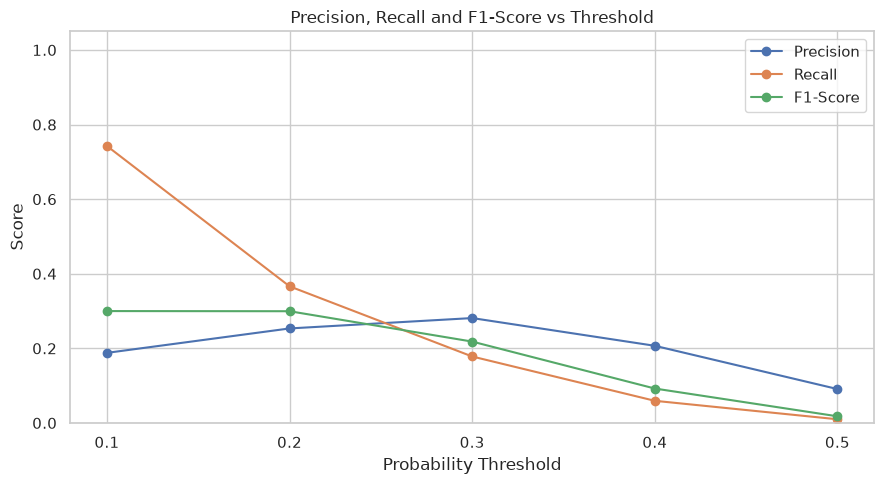

In [153]:

# Precision, Recall and F1-Score at Different Thresholds

thresholds = [0.5, 0.4, 0.3, 0.2, 0.1]

precision_values = []
recall_values = []
f1_values = []

for threshold in thresholds:

    y_val_pred = (y_val_prob >= threshold).astype(int)

    precision_values.append(
        precision_score(y_val, y_val_pred, zero_division=0)
    )

    recall_values.append(
        recall_score(y_val, y_val_pred, zero_division=0)
    )

    f1_values.append(
        f1_score(y_val, y_val_pred, zero_division=0)
    )

plt.figure(figsize=(9, 5))

plt.plot(
    thresholds,
    precision_values,
    marker="o",
    label="Precision"
)

plt.plot(
    thresholds,
    recall_values,
    marker="o",
    label="Recall"
)

plt.plot(
    thresholds,
    f1_values,
    marker="o",
    label="F1-Score"
)

plt.title("Precision, Recall and F1-Score vs Threshold")
plt.xlabel("Probability Threshold")
plt.ylabel("Score")

plt.xticks(thresholds)
plt.ylim(0, 1.05)

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


## 9. Final held-out test evaluation

The validation experiments suggest using a balanced logistic regression model with a probability threshold of 0.4. We now train a fresh pipeline on the complete training split and evaluate it once on the held-out test waves.

The threshold is a decision rule applied to predicted probabilities:
- probability ≥ 0.4 → predict a mutual match;
- probability < 0.4 → predict no mutual match.

This threshold favours finding more positive cases, at the cost of more false positives.

In [154]:
# Create fresh pipeline
final_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

# Train on all original training data
final_pipeline.fit(X_train, y_train)

# Get probabilities for the positive class
y_test_prob = final_pipeline.predict_proba(X_test)[:, 1]

# Apply the selected threshold
y_test_pred = (y_test_prob >= 0.4).astype(int)

# Evaluate
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_test_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_test_pred))

print("Average Precision:", average_precision_score(y_test, y_test_prob))
print("ROC-AUC:", roc_auc_score(y_test, y_test_prob))

Confusion Matrix:
[[272 477]
 [ 34 105]]

Classification Report:
              precision    recall  f1-score   support

           0       0.89      0.36      0.52       749
           1       0.18      0.76      0.29       139

    accuracy                           0.42       888
   macro avg       0.53      0.56      0.40       888
weighted avg       0.78      0.42      0.48       888

Average Precision: 0.1937441925561318
ROC-AUC: 0.570064642544976


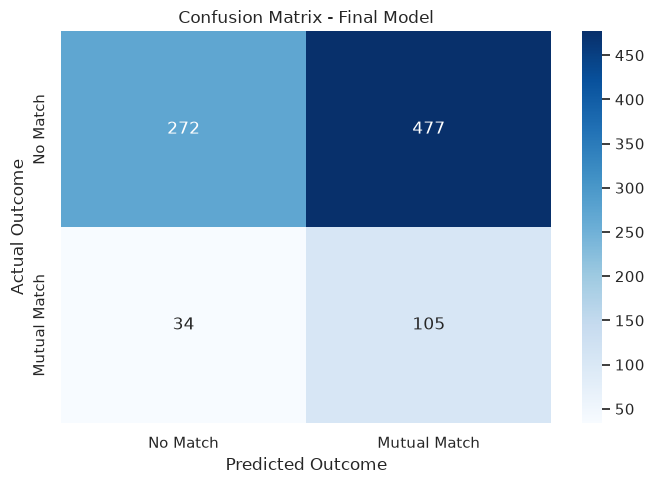

In [155]:

# Confusion Matrix Heatmap

cm = confusion_matrix(y_test, y_test_pred)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No Match", "Mutual Match"],
    yticklabels=["No Match", "Mutual Match"]
)

plt.title("Confusion Matrix - Final Model")
plt.xlabel("Predicted Outcome")
plt.ylabel("Actual Outcome")

plt.tight_layout()
plt.show()


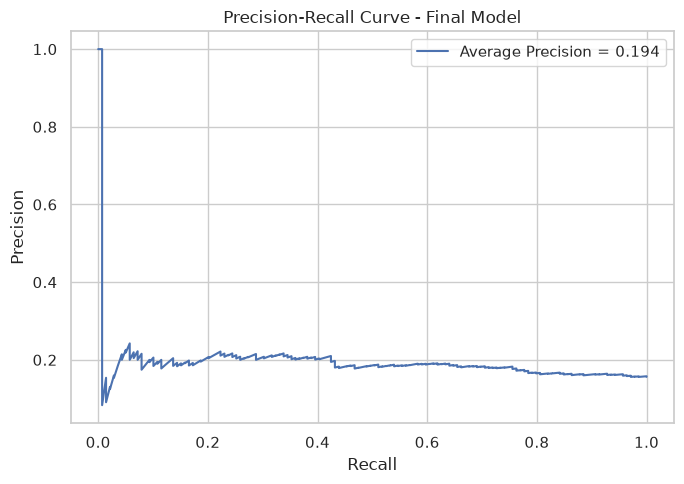

In [156]:

# Precision-Recall Curve - Final Model

from sklearn.metrics import precision_recall_curve

precision_curve, recall_curve, pr_thresholds = (
    precision_recall_curve(
        y_test,
        y_test_prob
    )
)

average_precision = average_precision_score(
    y_test,
    y_test_prob
)

plt.figure(figsize=(7, 5))

plt.plot(
    recall_curve,
    precision_curve,
    label=f"Average Precision = {average_precision:.3f}"
)

plt.title("Precision-Recall Curve - Final Model")
plt.xlabel("Recall")
plt.ylabel("Precision")

plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


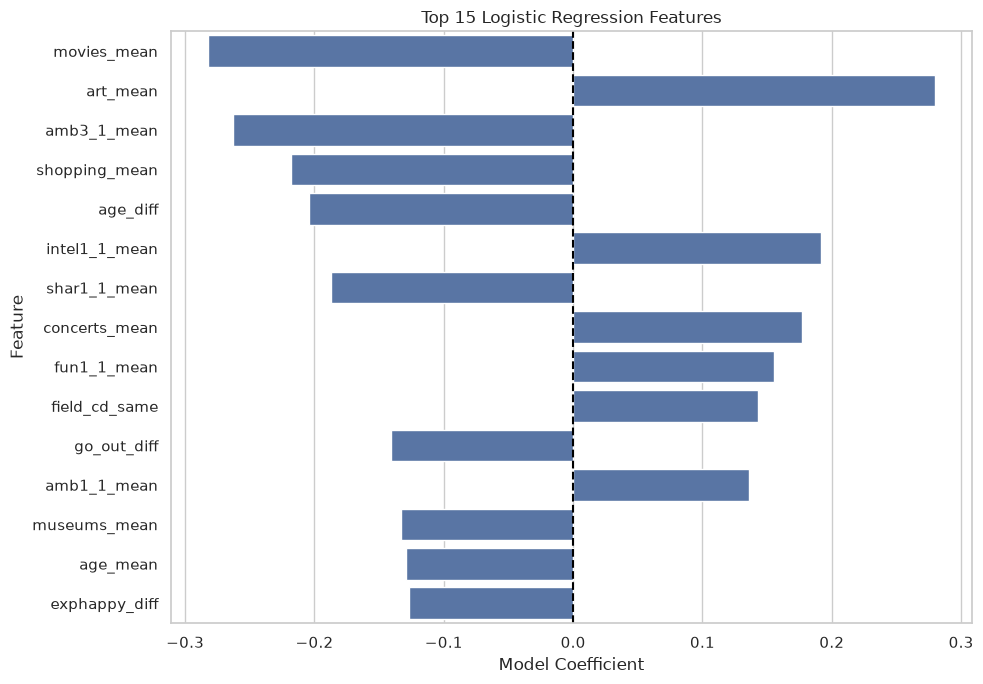

In [157]:

# Logistic Regression Feature Coefficients

feature_names = X_train.columns

coefficients = final_pipeline.named_steps["model"].coef_[0]

feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Coefficient": coefficients
})

feature_importance["Absolute Coefficient"] = (
    feature_importance["Coefficient"].abs()
)

top_features = feature_importance.sort_values(
    "Absolute Coefficient",
    ascending=False
).head(15)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Coefficient",
    y="Feature"
)

plt.title("Top 15 Logistic Regression Features")
plt.xlabel("Model Coefficient")
plt.ylabel("Feature")

plt.axvline(
    0,
    color="black",
    linestyle="--"
)

plt.tight_layout()
plt.show()


## 10. Results and interpretation

### What the final test result tells us

The held-out test evaluation should be interpreted using the confusion matrix and the positive-class metrics, not accuracy alone.

- **Recall for matches** measures the fraction of actual mutual matches that the model identifies.
- **Precision for matches** measures the fraction of predicted matches that are truly mutual matches.
- **Average precision** summarises the precision–recall trade-off across thresholds.
- **ROC-AUC** measures ranking discrimination across thresholds.

A high recall with low precision means the model finds many actual matches but also recommends many pairs that do not mutually match. This is not yet a reliable matchmaking system.

### Limitations and next steps

1. **Limited model scope:** This first project uses logistic regression, as required by the project constraints. More expressive models have not been explored.
2. **Class imbalance:** Mutual matches are a minority class, so accuracy can look acceptable even when the model misses most matches.
3. **Feature limitations:** The engineered features summarise similarity and participant preferences, but may not capture interaction dynamics, context, or nonlinear compatibility.
4. **Generalisation:** A wave-based split is a useful stricter test, but performance can vary depending on which waves are held out.
5. **Threshold trade-off:** Lowering the threshold increases recall but also increases false positives. A matchmaking product would need to decide how costly each type of error is.
6. **Historical dataset:** Results on this dataset do not establish that the model will work for a modern dating platform or for users outside the study.

### Conclusion

This project establishes an end-to-end baseline for strategic matchmaking: raw interactions are converted into unique reciprocal pairs, participant attributes are transformed into symmetric pair features, and a logistic regression pipeline is trained and evaluated without mixing event waves across splits.

The current model is a **first baseline, not a deployment-ready recommender**. Its main value is demonstrating the complete machine-learning workflow and revealing the difficulty of predicting mutual decisions from limited pre-date information.